# Prédiction du churn télécom : notebook Data Science

**Projet fil rouge MLOps, ESMT**

L'objectif de ce notebook est de comprendre les données clients d'un opérateur télécom, puis de construire et comparer plusieurs modèles capables de repérer à l'avance les clients susceptibles de partir.

Il suit le cheminement classique d'une démarche Data Science :

1. Chargement et contrôle qualité des données
2. Analyse exploratoire
3. Préparation et découpage train / test
4. Entraînement et comparaison de trois modèles
5. Analyse du modèle retenu
6. Conclusions et passage à l'industrialisation

Le script `src/train.py` reprend exactement la même logique pour produire le modèle servi par l'API. Ce notebook sert à l'explorer et à justifier les choix.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

# Le notebook fonctionne qu'on le lance depuis la racine du projet ou depuis notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data" / "raw" / "churn.csv"
RANDOM_STATE = 42

## 1. Chargement et contrôle qualité

Le jeu de données contient 2 000 clients décrits par six variables, et la cible `churn` (1 si le client est parti, 0 sinon).

In [2]:
df = pd.read_csv(DATA)
print("Dimensions :", df.shape)
df.head()

Dimensions : (2000, 7)


,age,anciennete,revenu,nb_reclamations,montant_mensuel,retards_paiement,churn
0,56,93,407324,2,35104,3,0
1,69,64,869449,0,42594,1,0
2,46,44,904651,3,8664,2,0
3,32,53,808681,4,15528,2,0
4,60,24,580599,4,33190,1,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   age               2000 non-null   int64
 1   anciennete        2000 non-null   int64
 2   revenu            2000 non-null   int64
 3   nb_reclamations   2000 non-null   int64
 4   montant_mensuel   2000 non-null   int64
 5   retards_paiement  2000 non-null   int64
 6   churn             2000 non-null   int64
dtypes: int64(7)
memory usage: 109.5 KB


In [4]:
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())
print("\nLignes dupliquées :", df.duplicated().sum())

Valeurs manquantes par colonne :
age                 0
anciennete          0
revenu              0
nb_reclamations     0
montant_mensuel     0
retards_paiement    0
churn               0
dtype: int64

Lignes dupliquées : 0


Aucune valeur manquante ni doublon : les données sont exploitables telles quelles, sans étape de nettoyage.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,2000.0,43.806,14.929,18.0,31.00,44.0,56.00,69.0
anciennete,2000.0,58.779,34.800,1.0,28.00,58.0,89.00,119.0
revenu,2000.0,583363.915,244511.528,150159.0,372126.75,580185.5,797360.25,999776.0
nb_reclamations,2000.0,1.948,1.323,0.0,1.00,2.0,3.00,8.0
montant_mensuel,2000.0,38699.851,20235.282,5005.0,21335.50,38165.5,56366.50,74963.0
retards_paiement,2000.0,1.012,1.006,0.0,0.00,1.0,2.00,6.0
churn,2000.0,0.430,0.495,0.0,0.00,0.0,1.00,1.0


Quelques repères utiles pour la suite :

* l'**ancienneté** va de 1 à 119 mois ;
* le **revenu** et le **montant mensuel** sont exprimés en francs guinéens, sur des échelles très différentes des autres variables, ce qui justifiera une standardisation pour la régression logistique ;
* les **réclamations** et les **retards de paiement** sont des comptages, avec une moyenne autour de 2 et de 1.

## 2. Analyse exploratoire

### 2.1 La variable cible

       clients  part
churn               
0         1139  0.57
1          861  0.43


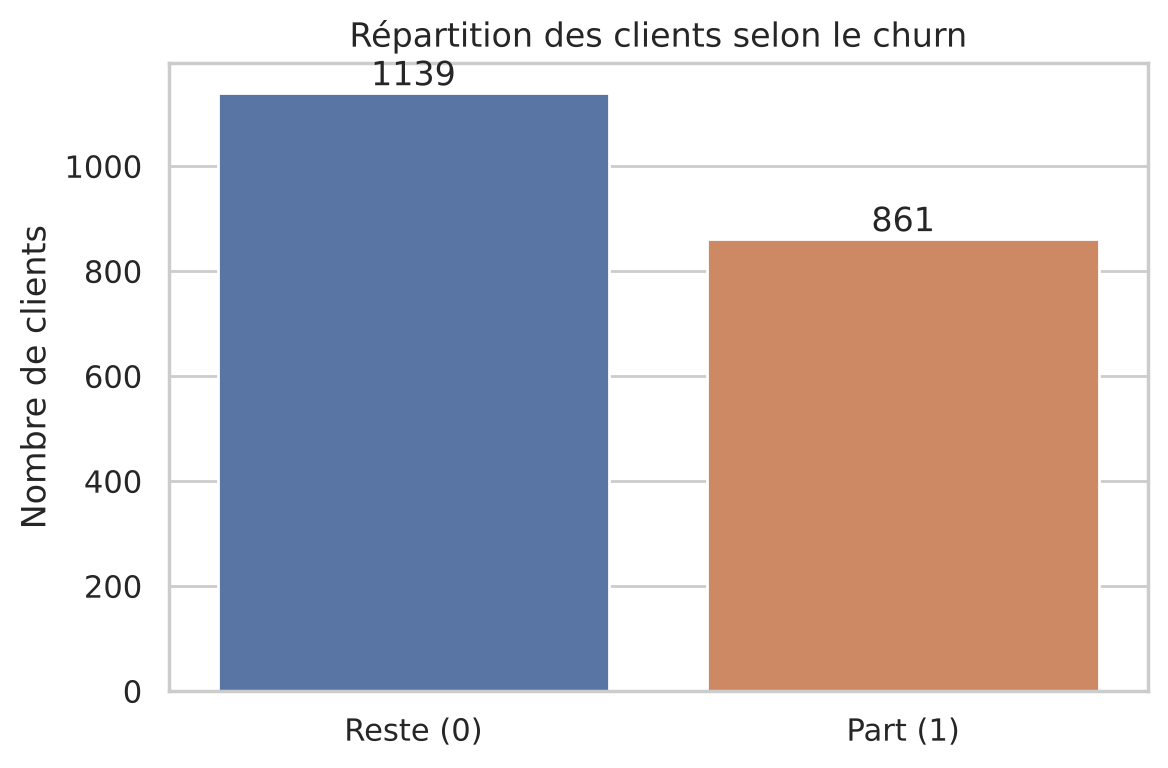

In [6]:
counts = df["churn"].value_counts().sort_index()
rates = df["churn"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"clients": counts, "part": rates.round(3)}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="churn", hue="churn", palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
ax.set_xticks([0, 1], ["Reste (0)", "Part (1)"])
ax.set_xlabel("")
ax.set_ylabel("Nombre de clients")
ax.set_title("Répartition des clients selon le churn")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

43 % des clients sont partis. Les deux classes sont assez équilibrées, on n'a donc pas besoin de rééchantillonnage. On gardera tout de même un découpage **stratifié** pour conserver cette proportion dans les jeux d'entraînement et de test.

### 2.2 Profil moyen des clients qui partent

In [7]:
profil = df.groupby("churn").mean().T
profil.columns = ["Reste", "Part"]
profil["Écart (%)"] = ((profil["Part"] / profil["Reste"] - 1) * 100).round(1)
profil

,Reste,Part,Écart (%)
age,43.595,44.084,1.1
anciennete,66.178,48.991,-26.0
revenu,583472.464,583220.317,-0.0
nb_reclamations,1.931,1.972,2.1
montant_mensuel,36660.500,41397.670,12.9
retards_paiement,0.968,1.070,10.5


Le contraste est net sur l'**ancienneté** : les clients qui partent ont en moyenne 49 mois d'ancienneté, contre 66 pour ceux qui restent. Ils paient aussi une facture mensuelle plus élevée (environ 13 % de plus) et ont un peu plus de retards de paiement. Les réclamations ne diffèrent que très légèrement, et l'âge comme le revenu sont quasiment identiques dans les deux groupes.

### 2.3 Corrélations

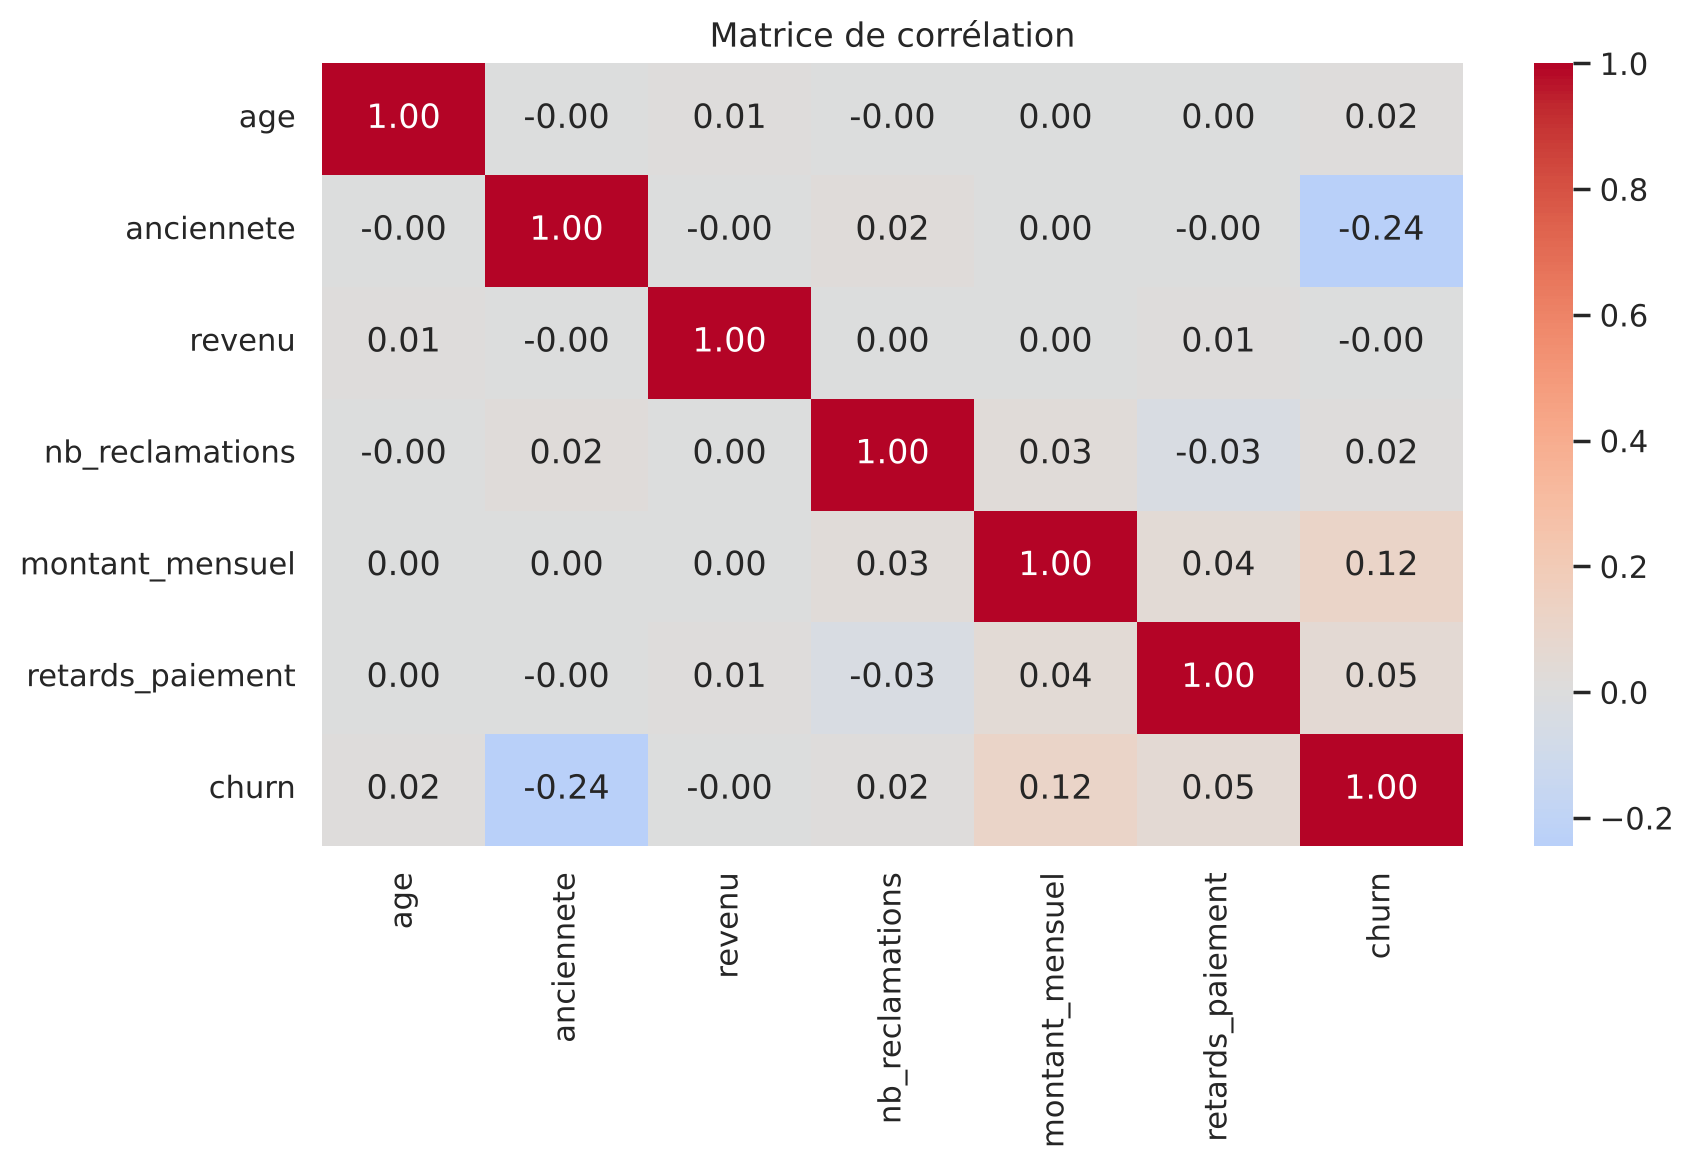

anciennete         -0.245
montant_mensuel     0.116
retards_paiement    0.050
age                 0.016
nb_reclamations     0.016
revenu             -0.001
Name: churn, dtype: float64


In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matrice de corrélation")
plt.tight_layout()
plt.show()

print(df.corr()["churn"].drop("churn").sort_values(key=abs, ascending=False).round(3))

La matrice confirme la lecture précédente. L'ancienneté est de loin la variable la plus liée au churn (corrélation de -0,25 : plus un client est ancien, moins il part). Viennent ensuite le montant mensuel (0,12) puis les retards de paiement (0,05). Les réclamations ont un lien très faible, et l'âge comme le revenu n'ont aucun lien avec le départ : ils apportent surtout du bruit.

Les variables explicatives ne sont pas corrélées entre elles, il n'y a donc pas de problème de colinéarité.

### 2.4 Distributions selon le churn

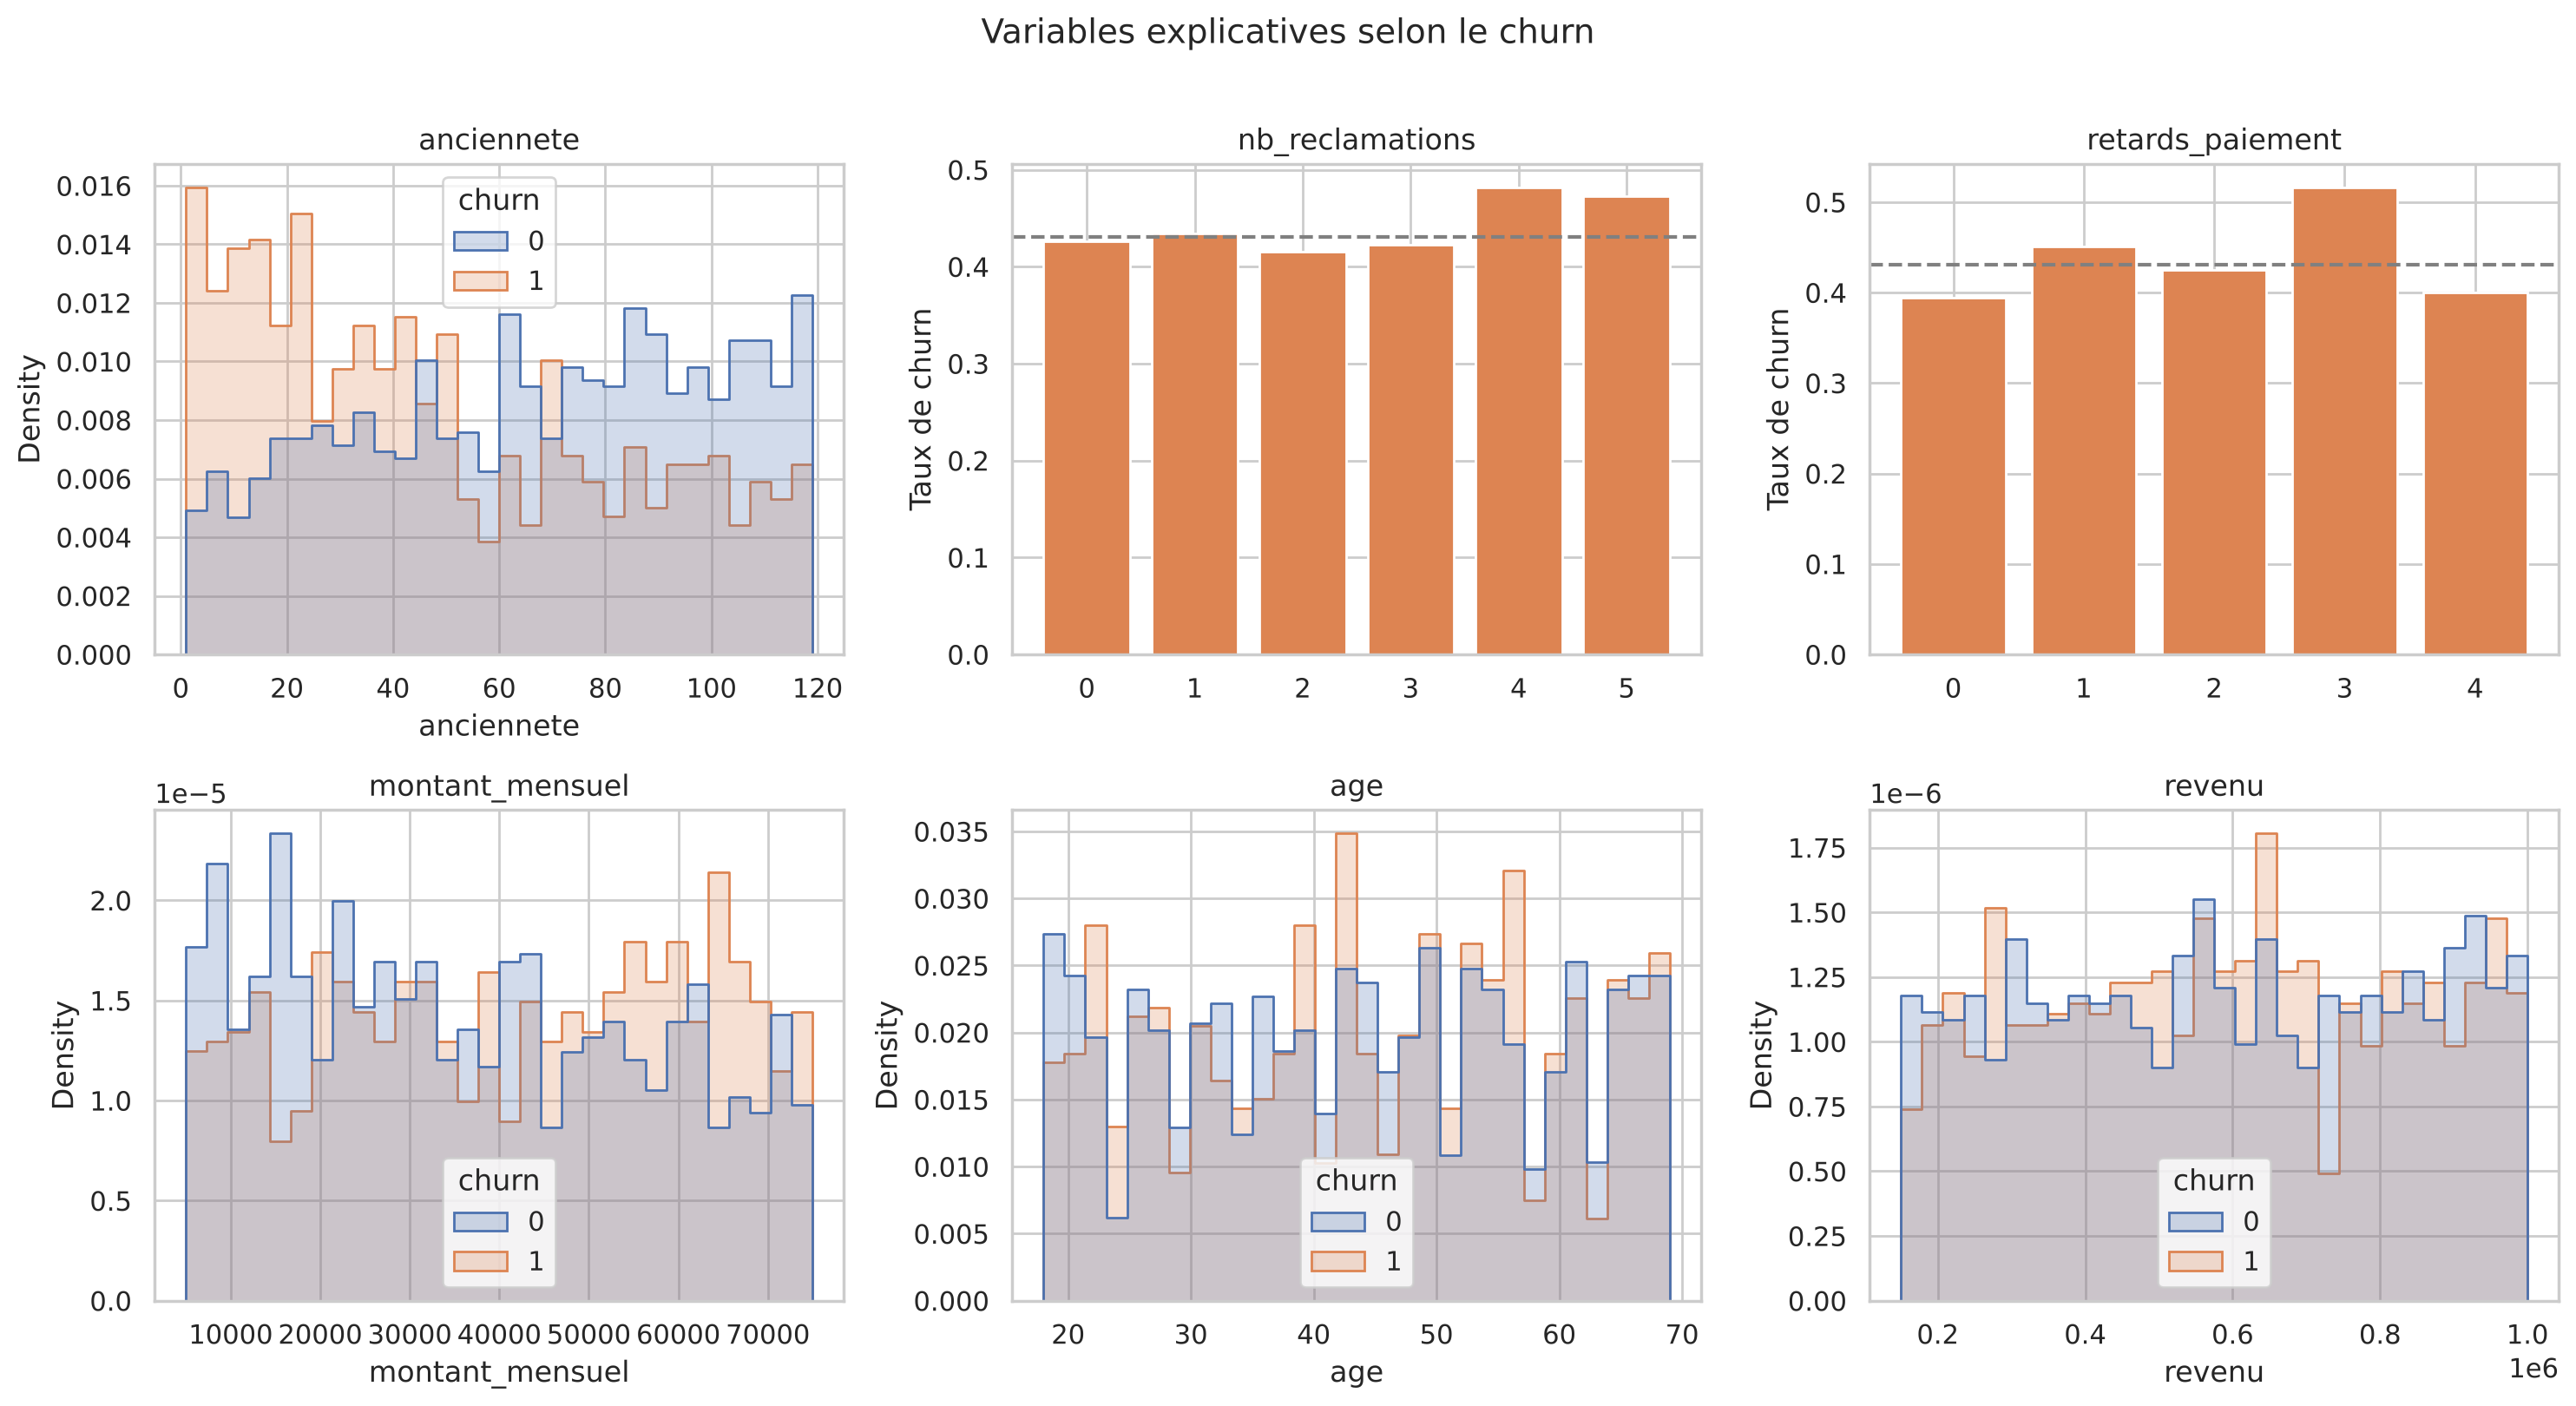

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["anciennete", "nb_reclamations", "retards_paiement",
                                  "montant_mensuel", "age", "revenu"]):
    if df[col].nunique() < 15:
        rate = df.groupby(col)["churn"].agg(["mean", "size"])
        rate = rate[rate["size"] >= 20]
        ax.bar(rate.index, rate["mean"], color="#DD8452")
        ax.set_ylabel("Taux de churn")
        ax.axhline(df["churn"].mean(), ls="--", c="grey")
    else:
        sns.histplot(data=df, x=col, hue="churn", bins=30, element="step",
                     stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
plt.suptitle("Variables explicatives selon le churn", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

In [10]:
df["tranche_anciennete"] = pd.cut(df["anciennete"], bins=[0, 12, 24, 48, 84, 120],
                                  labels=["< 1 an", "1 à 2 ans", "2 à 4 ans", "4 à 7 ans", "7 ans et +"])
tab = df.groupby("tranche_anciennete", observed=True)["churn"].agg(clients="size", taux_churn="mean")
tab["taux_churn"] = (tab["taux_churn"] * 100).round(1)
df = df.drop(columns="tranche_anciennete")
tab

,clients,taux_churn
tranche_anciennete,,
< 1 an,214,66.8
1 à 2 ans,230,59.6
2 à 4 ans,409,48.7
4 à 7 ans,566,36.2
7 ans et +,581,30.5


Le taux de churn baisse régulièrement avec l'ancienneté : deux clients sur trois partent pendant leur première année, contre moins d'un sur trois au delà de sept ans. La première année est clairement la période à risque, ce qui est une information directement exploitable par les équipes de fidélisation : un client récent, avec une facture élevée et des retards de paiement, mérite une attention prioritaire.

**Ce qu'il faut retenir de l'exploration**

* Le signal est réel mais modéré : aucune variable ne sépare franchement les deux groupes.
* L'ancienneté porte l'essentiel de l'information, complétée par le montant mensuel et les retards de paiement.
* L'âge et le revenu ne semblent pas utiles. On les conserve dans le modèle pour rester fidèle au contrat d'interface de l'API, mais c'est une piste de simplification.

## 3. Préparation des données

On sépare les variables explicatives de la cible, puis on réserve 20 % des clients pour l'évaluation finale. L'ordre des colonnes est fixé une fois pour toutes : l'API devra envoyer exactement les mêmes colonnes, dans le même ordre.

In [11]:
FEATURES = ["age", "anciennete", "revenu", "nb_reclamations", "montant_mensuel", "retards_paiement"]
TARGET = "churn"

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Entraînement : {X_train.shape[0]} clients, taux de churn {y_train.mean():.1%}")
print(f"Test         : {X_test.shape[0]} clients, taux de churn {y_test.mean():.1%}")

Entraînement : 1600 clients, taux de churn 43.1%
Test         : 400 clients, taux de churn 43.0%


La stratification a bien conservé le même taux de churn dans les deux jeux.

## 4. Entraînement et comparaison de trois modèles

On compare trois familles de modèles de classification :

* une **régression logistique**, précédée d'une standardisation des variables ;
* un **arbre de décision**, limité à 5 niveaux pour rester lisible ;
* une **forêt aléatoire**, régularisée (profondeur 6, au moins 10 clients par feuille) pour éviter qu'elle n'apprenne le bruit par cœur.

Le choix du modèle se fait sur le **F1 moyen en validation croisée à 5 plis**, calculé uniquement sur le jeu d'entraînement. Le jeu de test reste ainsi totalement neutre et ne sert qu'à l'évaluation finale. Le F1 est préféré à l'accuracy parce qu'il équilibre précision et rappel sur la classe qui nous intéresse : les clients qui partent.

In [12]:
models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=1000))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=10,
                                            random_state=RANDOM_STATE, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Précision": precision_score(y_test, pred),
        "Rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, proba),
        "F1 CV (moyenne)": cv_f1.mean(),
        "F1 CV (écart type)": cv_f1.std(),
    })

results = pd.DataFrame(rows).set_index("Modèle").round(3)
results

,Accuracy,Précision,Rappel,F1,ROC AUC,F1 CV (moyenne),F1 CV (écart type)
Modèle,,,,,,,
Logistic Regression,0.625,0.582,0.453,0.510,0.636,0.523,0.047
Decision Tree,0.632,0.583,0.512,0.545,0.623,0.436,0.088
Random Forest,0.635,0.618,0.395,0.482,0.639,0.478,0.047


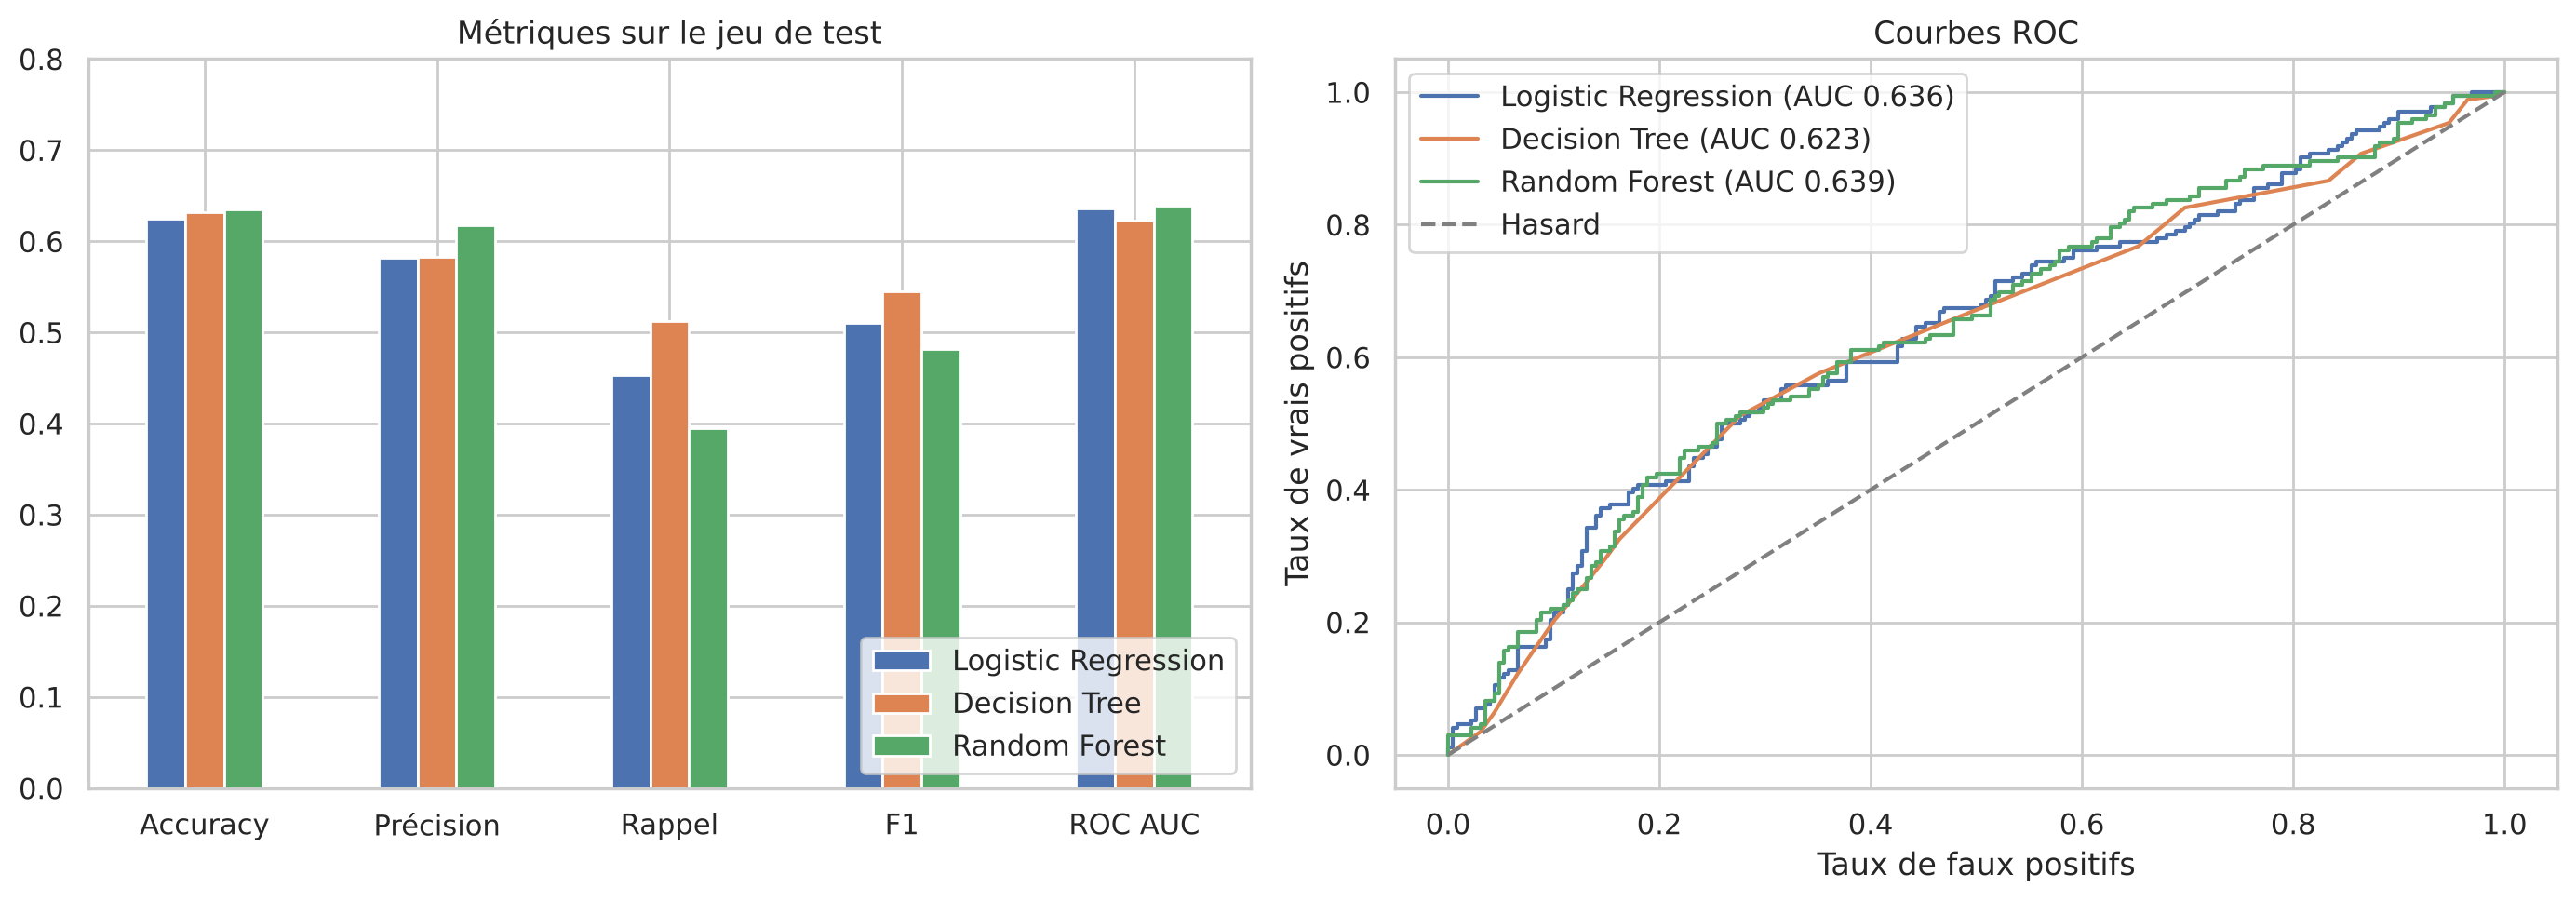

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results[["Accuracy", "Précision", "Rappel", "F1", "ROC AUC"]].T.plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0, 0.8)
axes[0].set_title("Métriques sur le jeu de test")
axes[0].legend(loc="lower right")

for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {results.loc[name, 'ROC AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], "--", c="grey", label="Hasard")
axes[1].set_xlabel("Taux de faux positifs")
axes[1].set_ylabel("Taux de vrais positifs")
axes[1].set_title("Courbes ROC")
axes[1].legend()
plt.tight_layout()
plt.show()

In [14]:
best_name = results["F1 CV (moyenne)"].idxmax()
print("Modèle retenu :", best_name)

Modèle retenu : Logistic Regression


**Lecture des résultats**

Sur le jeu de test, les trois modèles sont proches, autour de 63 % d'accuracy et 0,63 à 0,64 de ROC AUC. C'est la validation croisée qui fait la différence : la régression logistique obtient le meilleur F1 moyen (0,523) avec une variance faible, alors que l'arbre de décision est très instable d'un pli à l'autre.

Ce résultat est logique : les données ont été générées à partir d'une formule logistique, le modèle linéaire est donc naturellement le mieux adapté. Sur des données réelles, avec des interactions et des effets non linéaires, la forêt aléatoire pourrait reprendre l'avantage. C'est pour cela que le script d'entraînement choisit le modèle sur les résultats plutôt que de l'imposer à l'avance.

Le score reste modeste (ROC AUC proche de 0,64), car le dataset contient beaucoup d'aléa : pour une grande partie des clients, la probabilité théorique de départ est proche de 0,5. Le modèle fait néanmoins nettement mieux que le hasard.

## 5. Analyse du modèle retenu

              precision    recall  f1-score   support

       Reste      0.647     0.754     0.696       228
        Part      0.582     0.453     0.510       172

    accuracy                          0.625       400
   macro avg      0.614     0.604     0.603       400
weighted avg      0.619     0.625     0.616       400



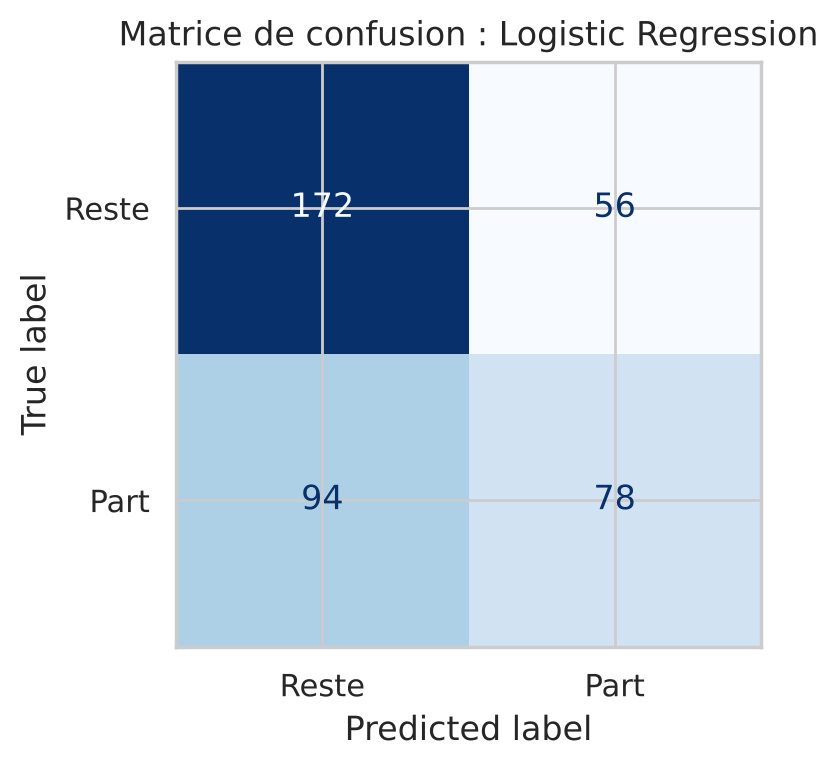

In [15]:
best = models[best_name]
pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=["Reste", "Part"], digits=3))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Reste", "Part"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matrice de confusion : {best_name}")
plt.tight_layout()
plt.show()

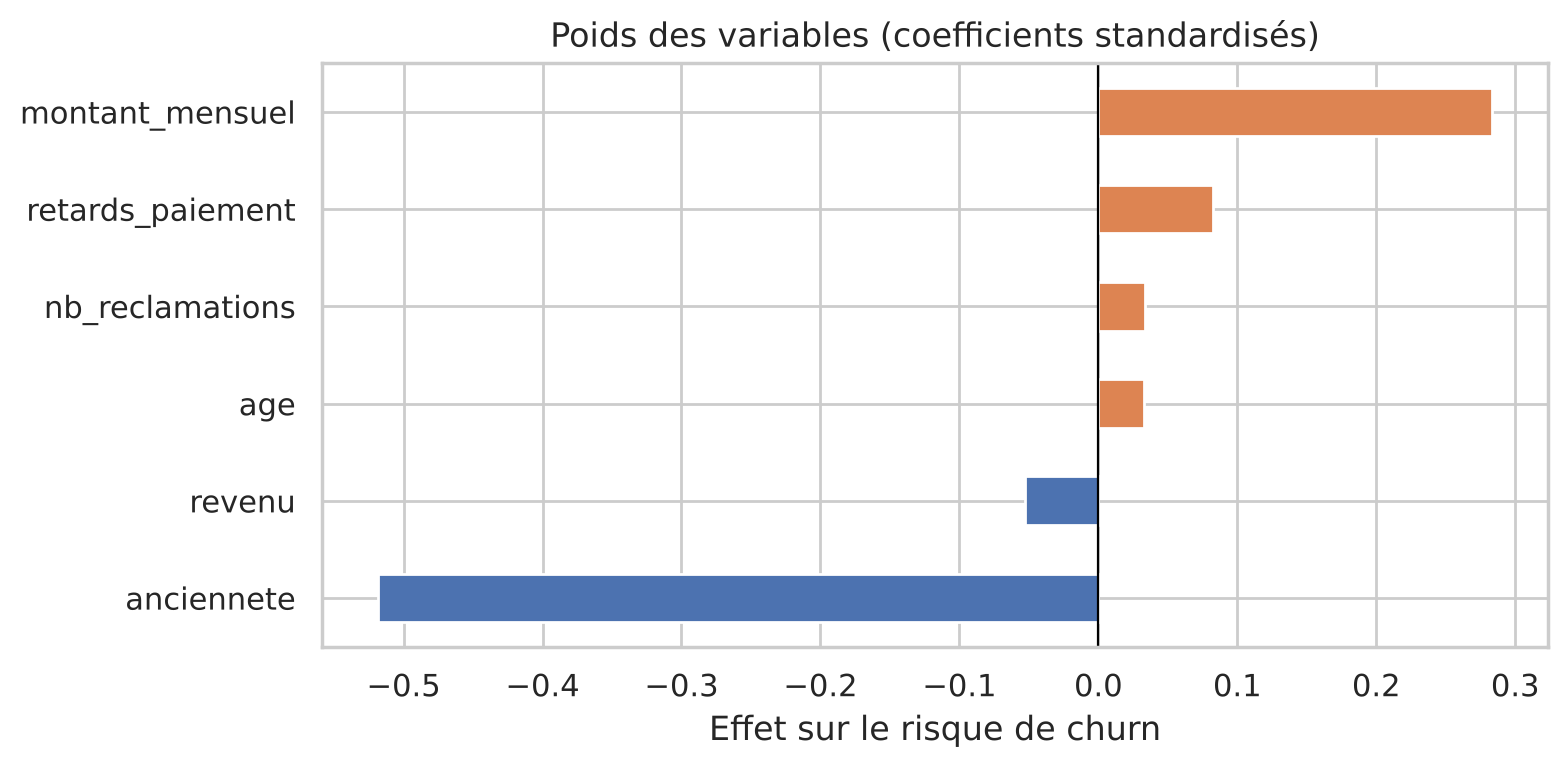

anciennete         -0.519
revenu             -0.053
age                 0.033
nb_reclamations     0.033
retards_paiement    0.083
montant_mensuel     0.283
dtype: float64

In [16]:
coefs = pd.Series(best.named_steps["model"].coef_[0], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
coefs.plot.barh(ax=ax, color=["#4C72B0" if c < 0 else "#DD8452" for c in coefs])
ax.axvline(0, c="black", lw=0.8)
ax.set_title("Poids des variables (coefficients standardisés)")
ax.set_xlabel("Effet sur le risque de churn")
plt.tight_layout()
plt.show()
coefs.round(3)

Les coefficients de la régression logistique se lisent directement, puisque les variables ont été standardisées. L'ancienneté a le poids le plus fort et fait baisser le risque. Le montant mensuel l'augmente nettement, les retards de paiement un peu. Les réclamations, l'âge et le revenu ont des poids proches de zéro, ce qui confirme l'analyse exploratoire.

En comparaison, voici l'importance des variables selon la forêt aléatoire :

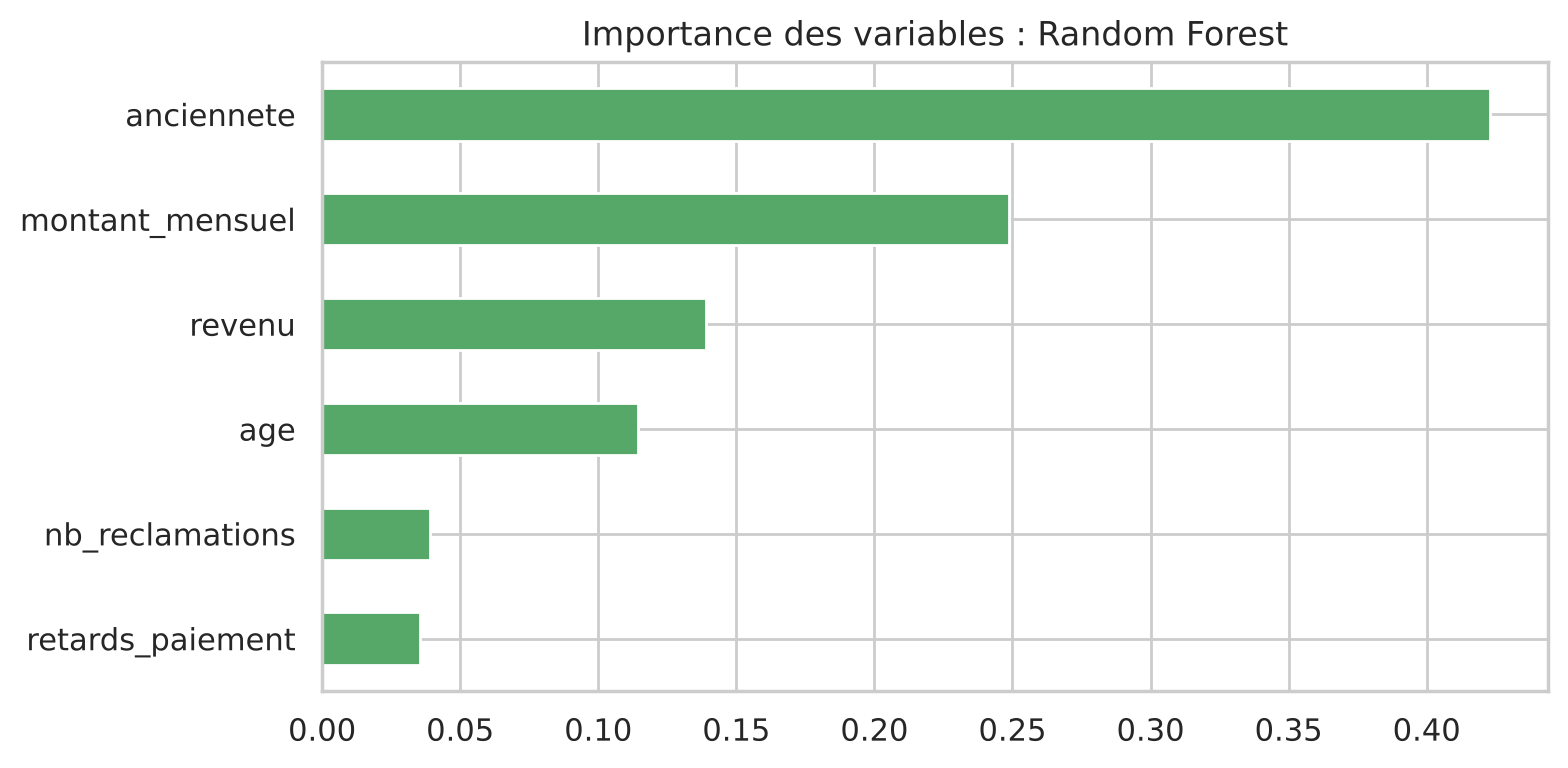

In [17]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=FEATURES).sort_values()
ax = imp.plot.barh(figsize=(8, 4), color="#55A868")
ax.set_title("Importance des variables : Random Forest")
plt.tight_layout()
plt.show()

La forêt aléatoire place elle aussi l'ancienneté puis le montant mensuel en tête. Elle donne en revanche un peu d'importance au revenu et à l'âge : c'est un biais connu de cette mesure, qui favorise les variables continues ayant beaucoup de valeurs distinctes, car l'arbre y trouve toujours des seuils pour découper le bruit. La corrélation nulle et les coefficients logistiques montrent que ces deux variables n'ont pas de vrai pouvoir prédictif.

### Test sur le client de l'énoncé

On vérifie la prédiction sur le client utilisé comme exemple dans l'énoncé et dans les tests de l'API.

In [18]:
client = pd.DataFrame([{"age": 35, "anciennete": 5, "revenu": 450000, "nb_reclamations": 2,
                        "montant_mensuel": 25000, "retards_paiement": 2}])[FEATURES]
proba = best.predict_proba(client)[0, 1]
print(f"Prédiction : {'CHURN' if proba >= 0.5 else 'NO_CHURN'} (probabilité {proba:.3f})")

Prédiction : CHURN (probabilité 0.599)


Le modèle prédit un départ avec une probabilité d'environ 0,60, ce qui correspond à la probabilité théorique de la formule de génération pour ce profil (client de cinq mois, deux retards et deux réclamations). L'énoncé annonçait 0,87, une valeur irréaliste pour ce client. C'est cette même valeur que renvoie l'API `/predict`.

### Cohérence avec le modèle déployé

In [19]:
meta_path = ROOT / "models" / "metadata.json"
if meta_path.exists():
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    print("Modèle servi par l'API :", meta["model_display_name"], "version", meta["model_version"])
    print("F1 CV enregistré       :", meta["metrics"]["cv_f1_mean"])
    print("F1 CV du notebook      :", round(results.loc[best_name, "F1 CV (moyenne)"], 4))

Modèle servi par l'API : Logistic Regression version 1.0.0
F1 CV enregistré       : 0.5231
F1 CV du notebook      : 0.523


Le notebook et le script d'entraînement aboutissent au même modèle et aux mêmes scores : l'exploration et la production sont alignées.

## 6. Conclusions

* Le churn touche 43 % des clients du jeu de données. Il est surtout lié à une **faible ancienneté**, puis à un **montant mensuel élevé** et aux **retards de paiement**.
* La **régression logistique** est retenue : meilleur F1 en validation croisée, résultats stables et coefficients faciles à expliquer aux équipes métier.
* La performance reste modérée (ROC AUC de 0,64) à cause du bruit du dataset. Le modèle est donc un outil de **priorisation** des clients à contacter, pas une certitude individuelle.
* Pistes d'amélioration : retirer l'âge et le revenu, voire les réclamations, ajuster le seuil de décision selon le coût d'une action de rétention, et réentraîner régulièrement sur des données réelles.

L'étape suivante est l'industrialisation : le script `src/train.py` sauvegarde ce modèle avec ses métadonnées, puis l'API FastAPI le sert, sous tests, conteneurisé et supervisé.